# <center> Overfitting on a single trial

In [14]:
import sys
from pathlib import Path

# Find project root = folder that contains "src"
p = Path().resolve()
while p != p.parent and not (p / "src").exists():
    p = p.parent

if not (p / "src").exists():
    raise RuntimeError("Cannot find project root (folder containing 'src').")

sys.path.insert(0, str(p))  # add project root

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_squared_error
from IPython.display import display
import pickle

import warnings
warnings.simplefilter("ignore", category=pd.errors.PerformanceWarning)

from pandas.errors import PerformanceWarning
warnings.filterwarnings("ignore", category=PerformanceWarning)

import os
os.environ["OMP_NUM_THREADS"] = "1"  # To limit CPU usage and avoid crashes
os.environ["MKL_NUM_THREADS"] = "1"


from src.preprocessing import preprocessing_pipeline
from src.model_NN import train_nn_pipeline
from src.sampling import sample_trajectory, generate_trajectory_video
from src import functions

cols_to_lag = [
    "f_speed",
    "d_ori",
    "min_dist_active",
    "mean_dist_active",
    "mean_angle_active",
    "lateral_balance",
    "n_active_stimuli",
    "is_dots_moving"
]


## Context

This notebook focuses on overfitting the model on a single fish and a single trial.
The goal is to diagnose whether the model formulation itself is capable of reproducing the fish’s intrinsic burst–glide–stop dynamics before evaluating more complex stimulus-related effects.

In [16]:
# We download the dict extracted from the pipeline
with open("abs_dict.pkl", "rb") as f:
    abs_dict = pickle.load(f)

df_abs = abs_dict["f0"]

df_abs = df_abs.rename(columns={
    "f0_x": "f_x",
    "f0_y": "f_y",
    "f0_ori": "f_ori"
})

df_abs["fish_id"] = 0

print("Dataframe shape : " + str(df_abs.shape))

Dataframe shape : (313500, 31)


Let's select a single trial

In [17]:
# 1) Detect onset
prev = df_abs['stimulus'].shift(1)
onset_idx = df_abs.index[(prev == "inter_stim_pause") & (df_abs['stimulus'] != "inter_stim_pause")][0]

# 2) find end of the trial
after = df_abs.loc[onset_idx:]
end_idx = after.index[after['stimulus'] == "inter_stim_pause"][0]
# garder uniquement ce premier trial
df_trial_base = df_abs.loc[onset_idx:end_idx - 1].copy()


In [18]:
print("Dataframe shape : " + str(df_trial_base.shape))

Dataframe shape : (1800, 31)


In [19]:
df_trial_base.head()

,frame,source_frame,stimulus,f_x,f_y,f_ori,d0_x,d0_y,d0_stim,d1_x,...,d5_x,d5_y,d5_stim,d6_x,d6_y,d6_stim,d7_x,d7_y,d7_stim,fish_id
1500,1500,1500,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,3.049185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,...,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,0
1501,1501,1501,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.117185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,...,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,0
1502,1502,1502,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.105185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,...,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,0
1503,1503,1503,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.081185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,...,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,0
1504,1504,1504,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.108185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,...,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,0


In [20]:
df, df_trial_base = preprocessing_pipeline(df_trial_base, cols_to_lag=cols_to_lag)

------------ Raw dataframe ------------
The dataset contains : 0.0% of NaN.
There are few NaN, therefore we make the choice to remove them.
✅ No highly correlated features found.
Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.
Created 144 lag features for 8 base columns, using lags from 5 to 90 frames (step=5, horizon ≈ 3.00 s at 30 fps).


✅ Temporal split complete:
  Train: 1324 rows (80.0%)
  Val:   165 rows (10.0%)
  Test:  166 rows (10.0%)
Epoch 1/10000 | Train loss: 0.709563 | Val loss: -0.493777
Epoch 2/10000 | Train loss: -0.934028 | Val loss: 0.453395
Epoch 3/10000 | Train loss: -1.038404 | Val loss: -0.675508
Epoch 4/10000 | Train loss: -1.158662 | Val loss: -0.500052
Epoch 5/10000 | Train loss: -1.126089 | Val loss: 0.136754
Epoch 6/10000 | Train loss: -1.221730 | Val loss: -0.570831
Epoch 7/10000 | Train loss: -1.241850 | Val loss: -0.656718
Epoch 8/10000 | Train loss: -1.255554 | Val loss: -0.597441
Epoch 9/10000 | Train loss: -1.285742 | Val loss: -0.167012
Epoch 10/10000 | Train loss: -1.227774 | Val loss: -0.714813
Epoch 11/10000 | Train loss: -1.302412 | Val loss: -0.677252
Epoch 12/10000 | Train loss: -1.262565 | Val loss: -0.713114
Epoch 13/10000 | Train loss: -1.337941 | Val loss: -0.385348
Epoch 14/10000 | Train loss: -1.334462 | Val loss: -0.606636
Epoch 15/10000 | Train loss: -1.355106 | Val loss: -

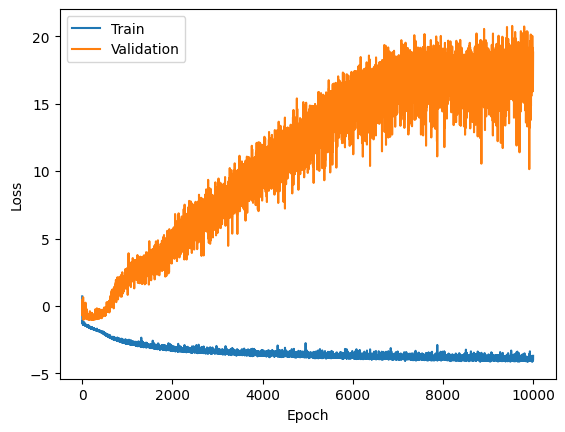

In [21]:
model, scalers, splits = train_nn_pipeline(df, early_stopping=False, num_epochs=10000)

## Test (with same data than train)

In [22]:
# =========================
# TEST RMSE (speed + d_ori)
# =========================

from torch.utils.data import TensorDataset, DataLoader
import torch

X_train_np = splits["train"]["X"].to_numpy(dtype="float32")

batch_size = 32  # change if you want

# 1) Build a FRESH test_loader that yields (x, y_speed, y_ori)

y_speed_train_np = splits["train"]["speed"].to_numpy(dtype="float32").reshape(-1, 1)
y_ori_train_np   = splits["train"]["d_ori"].to_numpy(dtype="float32").reshape(-1, 1)

test_dataset = TensorDataset(
    torch.from_numpy(X_train_np),
    torch.from_numpy(y_speed_train_np),
    torch.from_numpy(y_ori_train_np),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

# 2) Sanity check (must be 3)
b = next(iter(test_loader))
print("Batch length:", len(b))
print("Shapes:", [t.shape for t in b])  # expect: [(B,260), (B,1), (B,1)]

# 3) Eval + RMSE
model.eval()

all_pred_speed = []
all_true_speed = []
all_pred_ori   = []
all_true_ori   = []

with torch.no_grad():
    for x_test, y_test_speed, y_test_ori in test_loader:
        out = model(x_test)

        # Expect model outputs 5 params per sample:
        # [mu_st, sigma_st_raw, p_pos_raw, mu_ln, sigma_ln_raw]
        mu_st    = out[:, 0]
        p_pos    = torch.sigmoid(out[:, 2])
        mu_ln    = out[:, 3]
        sigma_ln_raw = torch.nn.functional.softplus(out[:, 4]) + 1e-6
        
        sigma_min, sigma_max = 1e-3, 1.0  # à ajuster (souvent 0.3–1.5 max)
        sigma_ln = sigma_min + (sigma_max - sigma_min) * torch.sigmoid(sigma_ln_raw)

        # Orientation point prediction: Student-t mean
        mu_st = out[:, 0]
        sigma_st = torch.nn.functional.softplus(out[:, 1]) + 1e-6

        # Student-t sample: mu + sigma * t_nu
        t = torch.distributions.StudentT(df=5).sample(mu_st.shape).to(mu_st.device)
        pred_ori = mu_st + sigma_st * t

        # Speed point prediction: E[ZILN] = p_pos * exp(mu + 0.5*sigma^2)
        p_pos = torch.sigmoid(out[:, 2])
        mu_ln = out[:, 3]
        sigma_ln = sigma_min + (sigma_max - sigma_min) * torch.sigmoid(out[:, 4])  # raw -> sigmoid

        u = torch.rand_like(p_pos)
        b = (u < p_pos).float()  # Bernoulli
        pred_speed = b * torch.exp(mu_ln + sigma_ln * torch.randn_like(mu_ln))

        all_pred_speed.append(pred_speed)
        all_true_speed.append(y_test_speed.squeeze(-1))

        all_pred_ori.append(pred_ori)
        all_true_ori.append(y_test_ori.squeeze(-1))

all_pred_speed = torch.cat(all_pred_speed, dim=0)
all_true_speed = torch.cat(all_true_speed, dim=0)
all_pred_ori   = torch.cat(all_pred_ori, dim=0)
all_true_ori   = torch.cat(all_true_ori, dim=0)

rmse_speed = torch.sqrt(torch.mean((all_pred_speed - all_true_speed) ** 2))
rmse_ori   = torch.sqrt(torch.mean((all_pred_ori   - all_true_ori)   ** 2))


Batch length: 3
Shapes: [torch.Size([32, 203]), torch.Size([32, 1]), torch.Size([32, 1])]


# <center> RESULTS 

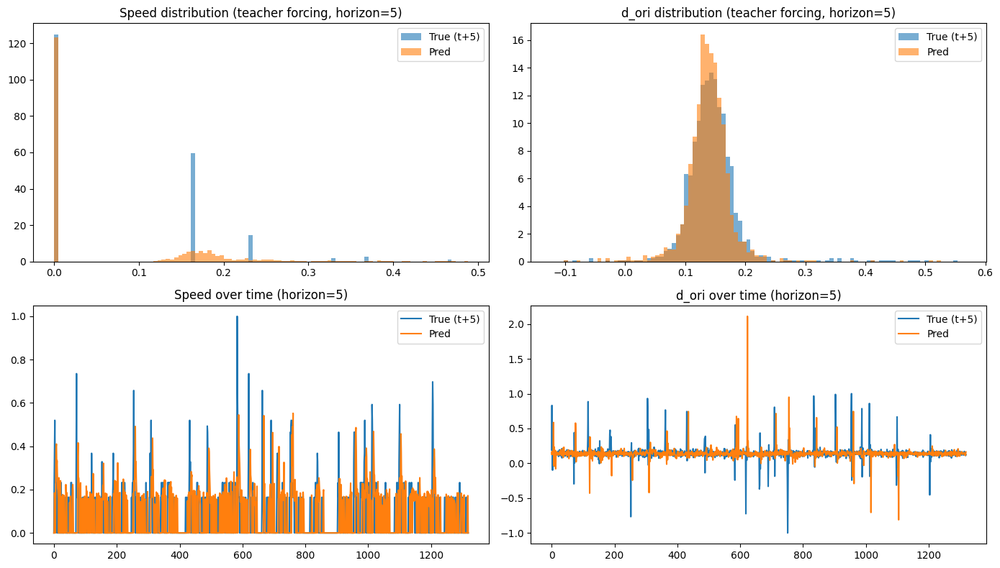

In [23]:
horizon = 5

# convert to numpy
pred_speed = all_pred_speed.detach().cpu().numpy()
true_speed = all_true_speed.detach().cpu().numpy()
pred_ori   = all_pred_ori.detach().cpu().numpy()
true_ori   = all_true_ori.detach().cpu().numpy()

# -------------------------
# Align properly (shift by horizon)
# -------------------------
n = min(len(pred_speed), len(true_speed) - horizon)

pred_speed = pred_speed[:n]
pred_ori   = pred_ori[:n]

true_speed_shifted = true_speed[horizon:horizon+n]
true_ori_shifted   = true_ori[horizon:horizon+n]

t = np.arange(n)

# -------------------------
# Robust zoom ranges
# -------------------------
speed_min = np.percentile(np.concatenate([true_speed_shifted, pred_speed]), 1)
speed_max = np.percentile(np.concatenate([true_speed_shifted, pred_speed]), 99)

ori_min = np.percentile(np.concatenate([true_ori_shifted, pred_ori]), 1)
ori_max = np.percentile(np.concatenate([true_ori_shifted, pred_ori]), 99)

# -------------------------
# Plot
# -------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# ---- Speed distribution ----
axes[0, 0].hist(true_speed_shifted, bins=100, range=(speed_min, speed_max),
                alpha=0.6, density=True, label="True (t+5)")
axes[0, 0].hist(pred_speed, bins=100, range=(speed_min, speed_max),
                alpha=0.6, density=True, label="Pred")
axes[0, 0].set_title("Speed distribution (teacher forcing, horizon=5)")
axes[0, 0].legend()

# ---- d_ori distribution ----
axes[0, 1].hist(true_ori_shifted, bins=100, range=(ori_min, ori_max),
                alpha=0.6, density=True, label="True (t+5)")
axes[0, 1].hist(pred_ori, bins=100, range=(ori_min, ori_max),
                alpha=0.6, density=True, label="Pred")
axes[0, 1].set_title("d_ori distribution (teacher forcing, horizon=5)")
axes[0, 1].legend()

# ---- Speed over time ----
axes[1, 0].plot(t, true_speed_shifted, label="True (t+5)")
axes[1, 0].plot(t, pred_speed, label="Pred")
axes[1, 0].set_title("Speed over time (horizon=5)")
axes[1, 0].legend()

# ---- d_ori over time ----
axes[1, 1].plot(t, true_ori_shifted, label="True (t+5)")
axes[1, 1].plot(t, pred_ori, label="Pred")
axes[1, 1].set_title("d_ori over time (horizon=5)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# <center> Video of the real behavior of the fish

Animation size has reached 20984490 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


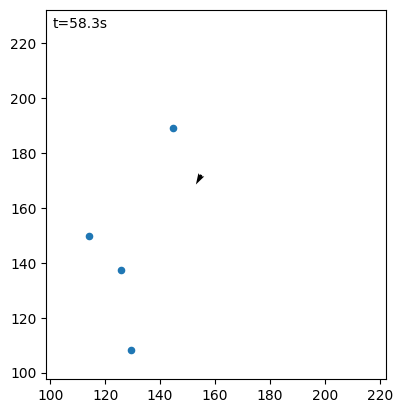

In [24]:
anim = generate_trajectory_video(df_trial_base, horizon_frames=1)
from IPython.display import HTML
HTML(anim.to_jshtml())

# <center> SAMPLING

In [25]:
window, prediction, param = sample_trajectory(df_trial_base, model, scalers, cols_to_lag=cols_to_lag)

Created 144 lag features for 8 base columns, using lags from 5 to 90 frames (step=5, horizon ≈ 3.00 s at 30 fps).


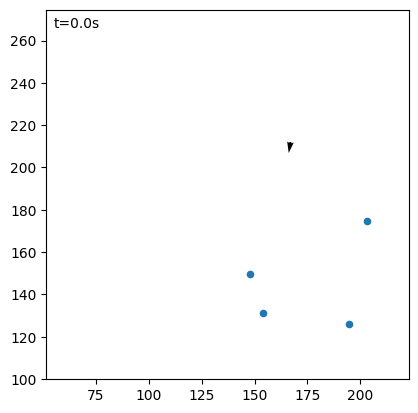

In [26]:
anim = generate_trajectory_video(window, horizon_frames=5)
from IPython.display import HTML
HTML(anim.to_jshtml())

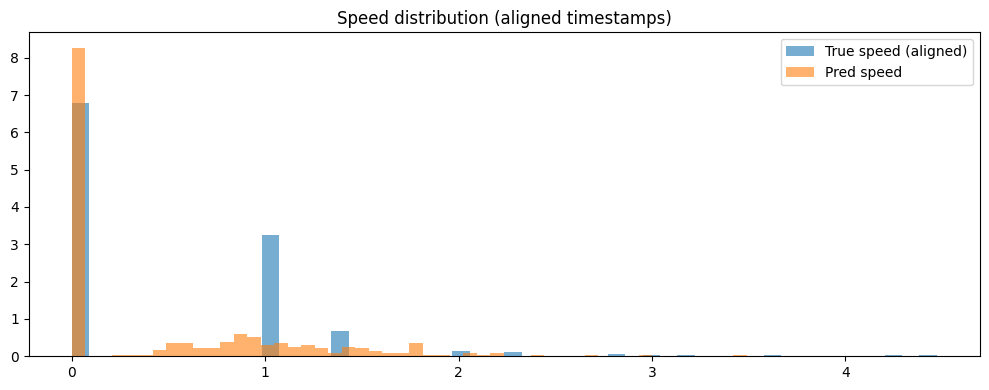

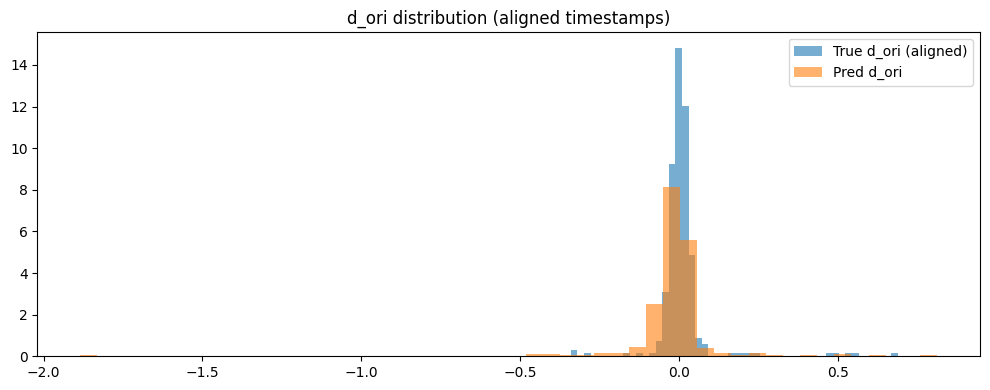

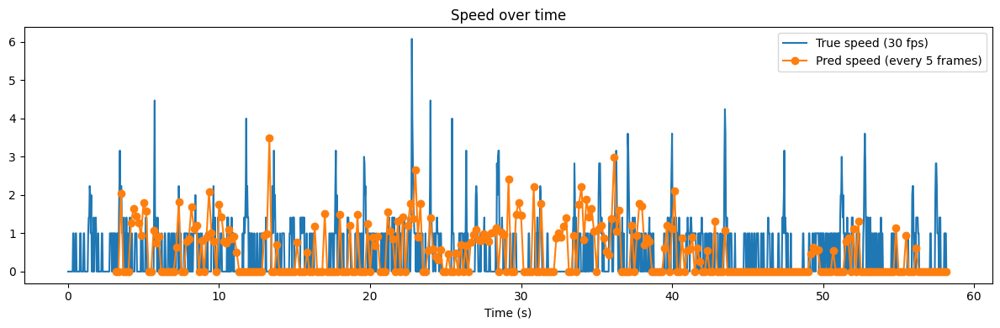

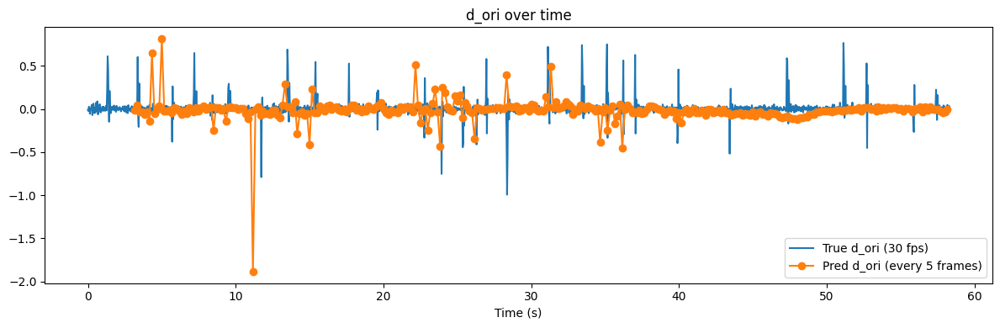

In [27]:
horizon_frames = 5
seed_len = int(3 * 30 + 1)
fps=30

# -------------------------
# 0) Prepare arrays
# -------------------------
pred_arr = np.asarray(prediction, dtype=float)
pred_speed = pred_arr[:, 0]
pred_dori  = pred_arr[:, 1]

# Make a clean positional index column
dfp = df_trial_base.copy()
dfp = dfp.reset_index(drop=False)  # keep old index in a column if you want
dfp["idx"] = np.arange(len(dfp))   # 0..N-1 (positional)

# -------------------------
# 1) Build the prediction timestamps (in frames)
# -------------------------
t0 = (seed_len - 1) + horizon_frames
t_pred_frames = t0 + np.arange(len(pred_speed)) * horizon_frames

# Keep only frames that exist in the trial
mask = t_pred_frames < len(dfp)
t_pred_frames = t_pred_frames[mask]
pred_speed = pred_speed[mask]
pred_dori  = pred_dori[mask]
t_pred_sec = t_pred_frames / float(fps)

# -------------------------
# 2) Extract TRUE series
# -------------------------
true_speed_full = dfp["f_speed"].to_numpy(dtype=float)
true_dori_full  = dfp["d_ori"].to_numpy(dtype=float)
t_full_sec      = dfp["idx"].to_numpy(dtype=float) / float(fps)

# True values at the SAME timestamps as predictions
true_speed_aligned = dfp.loc[dfp["idx"].isin(t_pred_frames), "f_speed"].to_numpy(dtype=float)
true_dori_aligned  = dfp.loc[dfp["idx"].isin(t_pred_frames), "d_ori"].to_numpy(dtype=float)

# Safety: ensure same length/order (isin can reorder); use iloc on positions instead
true_speed_aligned = dfp.iloc[t_pred_frames]["f_speed"].to_numpy(dtype=float)
true_dori_aligned  = dfp.iloc[t_pred_frames]["d_ori"].to_numpy(dtype=float)

# -------------------------
# 3) Plot A: Distributions (aligned)
# -------------------------
plt.figure(figsize=(10, 4))
plt.hist(true_speed_aligned, bins=50, alpha=0.6, density=True, label="True speed (aligned)")
plt.hist(pred_speed, bins=50, alpha=0.6, density=True, label="Pred speed")
plt.title("Speed distribution (aligned timestamps)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(true_dori_aligned, bins=50, alpha=0.6, density=True, label="True d_ori (aligned)")
plt.hist(pred_dori, bins=50, alpha=0.6, density=True, label="Pred d_ori")
plt.title("d_ori distribution (aligned timestamps)")
plt.legend()
plt.tight_layout()
plt.show()

# -------------------------
# 4) Plot B: Time series (full true + pred as points/line)
# -------------------------
plt.figure(figsize=(12, 4))
plt.plot(t_full_sec, true_speed_full, label="True speed (30 fps)")
plt.plot(t_pred_sec, pred_speed, marker="o", linestyle="-", label=f"Pred speed (every {horizon_frames} frames)")
plt.title("Speed over time")
plt.xlabel("Time (s)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t_full_sec, true_dori_full, label="True d_ori (30 fps)")
plt.plot(t_pred_sec, pred_dori, marker="o", linestyle="-", label=f"Pred d_ori (every {horizon_frames} frames)")
plt.title("d_ori over time")
plt.xlabel("Time (s)")
plt.legend()
plt.tight_layout()
plt.show()